<a href="https://colab.research.google.com/github/HusainAhmadKhan/E-commerce-Customer-Churn-Prediction/blob/main/E_Commerce_Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, classification_report

import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

**Problem Statement: Customer Churn Prediction**

In [ ]:
# CustomerID : A unique identifier for each customer
# Tenure : The duration in years for which the customer has been associated with the platform
# PreferredLoginDevice : The device preferred by the customer for logging into the ecommerce platform
# CityTier : The tier of the city where the customer resides
# WarehouseToHome : Distance in between warehouse to home of customer
# PreferredPaymentMode : The preferred mode of payment chosen by the customer
# Gender : The gender of customer
# HourSpendOnApp : The Number of hours spend on mobile application or website
# NumberOfDeviceRegistered : Total number of deceives is registered on particular customer
# PreferedOrderCat : Preferred order category of customer in last month
# SatisfactionScore : Satisfactory score of customer on service
# MaritalStatus : Marital status of customer
# NumberOfAddress : The number of addresses associated with the customer account
# Complain : Indicates whether the customer has lodged a complaint (1 for yes, 0 for no)
# OrderAmountHikeFromlastYear : Percentage increases in order from last year
# CouponUsed : Total number of coupon used by the customer
# OrderCount : Total number of orders placed by the customer
# DaySinceLastOrder : Day Since last order by customer
# CashbackAmount : The amount of cashback received by the customer

# Churn : Indicates whether the customer is going to churn (1 for yes, 0 for no), i.e, whether the customer will stop using the ecommerce
#                                                                                                                                platform


**Step 1 : Data Gather**

In [ ]:
df = pd.read_excel("/content/E Commerce Dataset (1).xlsx")
df

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5625,55626,0,10.0,Computer,1,30.0,Credit Card,Male,3.0,2,Laptop & Accessory,1,Married,6,0,18.0,1.0,2.0,4.0,150.71
5626,55627,0,13.0,Mobile Phone,1,13.0,Credit Card,Male,3.0,5,Fashion,5,Married,6,0,16.0,1.0,2.0,NaN,224.91
5627,55628,0,1.0,Mobile Phone,1,11.0,Debit Card,Male,3.0,2,Laptop & Accessory,4,Married,3,1,21.0,1.0,2.0,4.0,186.42
5628,55629,0,23.0,Computer,3,9.0,Credit Card,Male,4.0,5,Laptop & Accessory,4,Married,4,0,15.0,2.0,2.0,9.0,178.90


**Step 2 : EDA - Read and Explore the data**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [ ]:
df.describe()

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5630.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52815.500000,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,177.223030
std,1625.385339,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,49.207036
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51408.250000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,52815.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.280000
75%,54222.750000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.392500
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,324.990000


In [ ]:
df.isna().sum()

,0
CustomerID,0
Churn,0
Tenure,264
PreferredLoginDevice,0
CityTier,0
WarehouseToHome,251
PreferredPaymentMode,0
Gender,0
HourSpendOnApp,255
NumberOfDeviceRegistered,0


In [ ]:
df.isna().sum()*100 / len(df)

,0
CustomerID,0.000000
Churn,0.000000
Tenure,4.689165
PreferredLoginDevice,0.000000
CityTier,0.000000
WarehouseToHome,4.458259
PreferredPaymentMode,0.000000
Gender,0.000000
HourSpendOnApp,4.529307
NumberOfDeviceRegistered,0.000000


**Null value imputation**

In [ ]:
numerical_columns = ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount', 'Churn']

for column in list(numerical_columns):
  df[column].fillna(df[column].median(), inplace=True)


In [ ]:
df.isna().sum()*100 / len(df)

,0
CustomerID,0.0
Churn,0.0
Tenure,0.0
PreferredLoginDevice,0.0
CityTier,0.0
WarehouseToHome,0.0
PreferredPaymentMode,0.0
Gender,0.0
HourSpendOnApp,0.0
NumberOfDeviceRegistered,0.0


In [ ]:
for col in df.columns:
  print(col)
  print(df[col].unique())
  print("")

CustomerID
[50001 50002 50003 ... 55628 55629 55630]

Churn
[1 0]

Tenure
[ 4.  9.  0. 13. 11. 19. 20. 14.  8. 18.  5.  2. 30.  1. 23.  3. 29.  6.
 26. 28.  7. 24. 25. 10. 15. 22. 27. 16. 12. 21. 17. 50. 60. 31. 51. 61.]

PreferredLoginDevice
['Mobile Phone' 'Phone' 'Computer']

CityTier
[3 1 2]

WarehouseToHome
[  6.   8.  30.  15.  12.  22.  11.   9.  31.  18.  13.  20.  29.  28.
  26.  14.  10.  27.  17.  23.  33.  19.  35.  24.  16.  25.  32.  34.
   5.  21. 126.   7.  36. 127.]

PreferredPaymentMode
['Debit Card' 'UPI' 'CC' 'Cash on Delivery' 'E wallet' 'COD' 'Credit Card']

Gender
['Female' 'Male']

HourSpendOnApp
[3. 2. 1. 0. 4. 5.]

NumberOfDeviceRegistered
[3 4 5 2 1 6]

PreferedOrderCat
['Laptop & Accessory' 'Mobile' 'Mobile Phone' 'Others' 'Fashion' 'Grocery']

SatisfactionScore
[2 3 5 4 1]

MaritalStatus
['Single' 'Divorced' 'Married']

NumberOfAddress
[ 9  7  6  8  3  2  4 10  1  5 19 21 11 20 22]

Complain
[1 0]

OrderAmountHikeFromlastYear
[11. 15. 14. 23. 22. 16. 12. 13

In [ ]:
df['PreferredLoginDevice'].value_counts()

,count
PreferredLoginDevice,
Mobile Phone,2765
Computer,1634
Phone,1231


In [ ]:
### As moile phones and phones are same, let's merge them

In [ ]:
category_mapping = {'Phone' : 'Mobile Phone'}
df['PreferredLoginDevice'] = df['PreferredLoginDevice'].replace(category_mapping)
df['PreferredLoginDevice'].value_counts()

,count
PreferredLoginDevice,
Mobile Phone,3996
Computer,1634


In [ ]:
df.replace ({"PreferredLoginDevice" : {'Moile Phone' : 0, 'Computer': 1}}, inplace=True)

In [ ]:
df['PreferredPaymentMode'].value_counts()

,count
PreferredPaymentMode,
Debit Card,2314
Credit Card,1501
E wallet,614
UPI,414
COD,365
CC,273
Cash on Delivery,149


In [ ]:
### As Credit Card and CC are same, let's merge them
### As COD and Cash on Delivery are same, let's merge them

In [ ]:
category_mapping = {'CC' : 'Credit Card'}
df['PreferredPaymentMode'] = df['PreferredPaymentMode'].replace(category_mapping)
print(df['PreferredPaymentMode'].value_counts())

PreferredPaymentMode
Debit Card          2314
Credit Card         1774
E wallet             614
UPI                  414
COD                  365
Cash on Delivery     149
Name: count, dtype: int64


In [ ]:
category_mapping = {'Cash on Delivery' : 'COD'}
df['PreferredPaymentMode'] = df['PreferredPaymentMode'].replace(category_mapping)
print(df['PreferredPaymentMode'].value_counts())

PreferredPaymentMode
Debit Card     2314
Credit Card    1774
E wallet        614
COD             514
UPI             414
Name: count, dtype: int64


In [ ]:
df["Gender"].value_counts()

,count
Gender,
Male,3384
Female,2246


In [ ]:
df.replace({"Gender": {'Male' : 0, 'Female': 1}}, inplace=True)

In [ ]:
df['PreferedOrderCat'].value_counts()

,count
PreferedOrderCat,
Laptop & Accessory,2050
Mobile Phone,1271
Fashion,826
Mobile,809
Grocery,410
Others,264


In [ ]:
category_mapping = {'Mobile' : 'Mobile Phone'}
df['PreferedOrderCat'] = df['PreferedOrderCat'].replace(category_mapping)
df['PreferedOrderCat'].value_counts()

,count
PreferedOrderCat,
Mobile Phone,2080
Laptop & Accessory,2050
Fashion,826
Grocery,410
Others,264


In [ ]:
df['MaritalStatus'].value_counts()

,count
MaritalStatus,
Married,2986
Single,1796
Divorced,848


**Visualizing Numerical Columns**

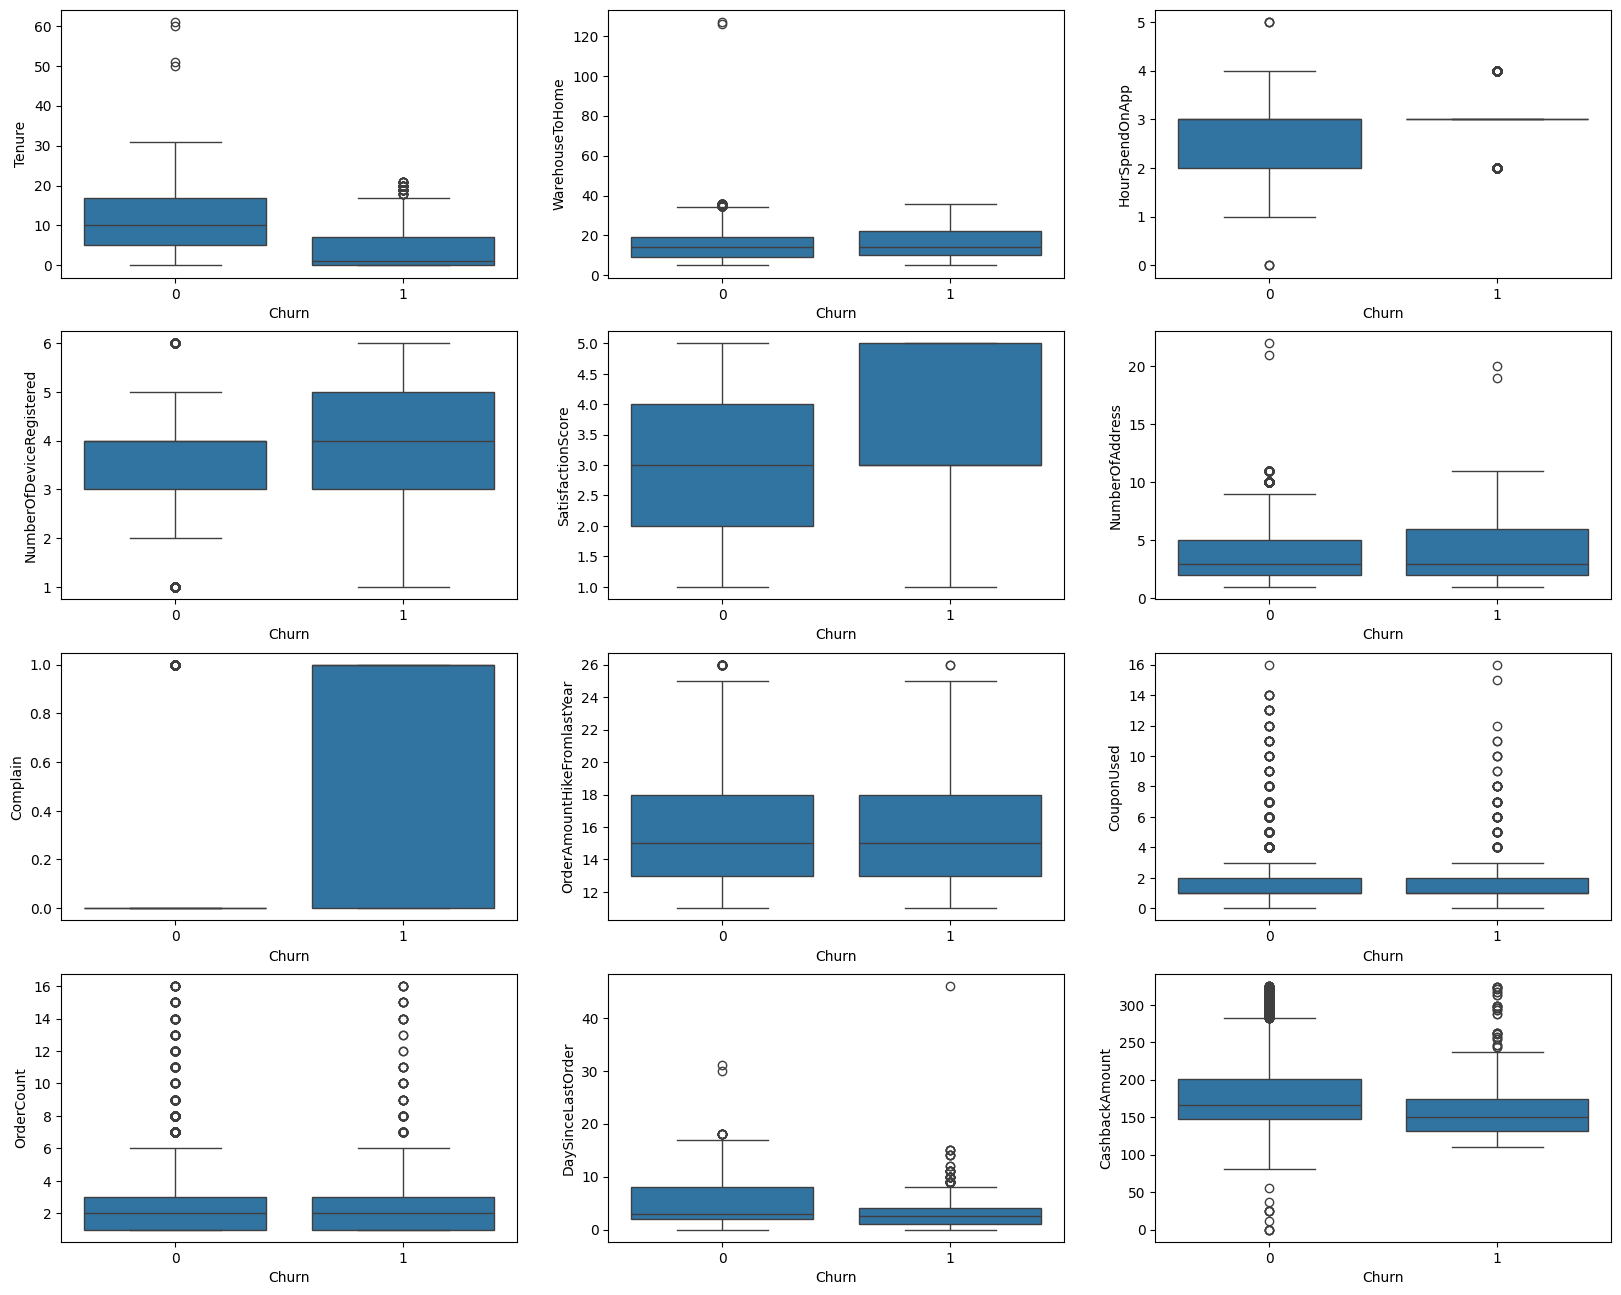

In [ ]:
plt.figure(figsize = (20, 16))
plt.subplot(4,3,1)
sns.boxplot(x='Churn', y='Tenure', data=df)
plt.subplot(4,3,2)
sns.boxplot(x='Churn', y='WarehouseToHome', data=df)
plt.subplot(4,3,3)
sns.boxplot(x='Churn', y='HourSpendOnApp', data=df)
plt.subplot(4,3,4)
sns.boxplot(x='Churn', y='NumberOfDeviceRegistered', data=df)
plt.subplot(4,3,5)
sns.boxplot(x='Churn', y='SatisfactionScore', data=df)
plt.subplot(4,3,6)
sns.boxplot(x='Churn', y='NumberOfAddress', data=df)
plt.subplot(4,3,7)
sns.boxplot(x='Churn', y='Complain', data=df)
plt.subplot(4,3,8)
sns.boxplot(x='Churn', y='OrderAmountHikeFromlastYear', data=df)
plt.subplot(4,3,9)
sns.boxplot(x='Churn', y='CouponUsed', data=df)
plt.subplot(4,3,10)
sns.boxplot(x='Churn', y='OrderCount', data=df)
plt.subplot(4,3,11)
sns.boxplot(x='Churn', y='DaySinceLastOrder', data=df)
plt.subplot(4,3,12)
sns.boxplot(x='Churn', y='CashbackAmount', data=df)

plt.show()


In [ ]:
categorical_features = ['PreferredPaymentMode', 'PreferedOrderCat', 'MaritalStatus' ]
numerical_features = ['Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

In [ ]:
df_features = df[numerical_features + categorical_features + ['Churn']]

**Step 3 : Create features from the data**

In [ ]:
def train_test_split_and_features(df_features):
  y = df_features['Churn']
  x = df_features.drop('Churn', axis=1)
  x = pd.get_dummies(x, dtype = int)
  x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

  print(x.head(5))
  print(x.columns)
  features = list(x.columns)
  return x_train, x_test, y_train, y_test, features



In [ ]:
x_train, x_test, y_train, y_test, features = train_test_split_and_features(df_features)

   Tenure  CityTier  WarehouseToHome  Gender  HourSpendOnApp  \
0     4.0         3              6.0       1             3.0   
1     9.0         1              8.0       0             3.0   
2     9.0         1             30.0       0             2.0   
3     0.0         3             15.0       0             2.0   
4     0.0         1             12.0       0             3.0   

   NumberOfDeviceRegistered  SatisfactionScore  NumberOfAddress  Complain  \
0                         3                  2                9         1   
1                         4                  3                7         1   
2                         4                  3                6         1   
3                         4                  5                8         0   
4                         3                  5                3         0   

   OrderAmountHikeFromlastYear  ...  PreferredPaymentMode_E wallet  \
0                         11.0  ...                              0   
1           

In [ ]:
x_train.head(10)

,Tenure,CityTier,WarehouseToHome,Gender,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,...,PreferredPaymentMode_E wallet,PreferredPaymentMode_UPI,PreferedOrderCat_Fashion,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single
4478,1.0,1,12.0,1,3.0,4,4,3,1,13.0,...,0,0,0,0,0,1,0,0,0,1
3685,17.0,1,13.0,1,4.0,5,3,3,1,15.0,...,0,0,0,0,1,0,0,0,0,1
731,0.0,1,9.0,0,3.0,4,3,2,0,12.0,...,0,0,0,0,0,1,0,0,0,1
291,9.0,1,8.0,0,2.0,3,2,2,1,23.0,...,0,0,0,0,0,1,0,1,0,0
184,4.0,1,11.0,0,2.0,3,2,1,1,12.0,...,0,0,0,0,0,1,0,1,0,0
1654,4.0,1,11.0,0,2.0,3,1,1,1,12.0,...,0,0,0,0,0,1,0,0,1,0
1533,7.0,1,8.0,0,2.0,4,3,2,0,17.0,...,0,0,0,0,1,0,0,0,1,0
2350,2.0,2,23.0,0,2.0,4,5,2,0,13.0,...,0,1,1,0,0,0,0,0,0,1
533,17.0,1,14.0,0,3.0,3,5,2,1,13.0,...,0,0,0,0,0,1,0,1,0,0
4981,23.0,3,15.0,0,3.0,5,4,8,0,18.0,...,0,0,0,1,0,0,0,0,1,0


**Step 4 : Fit and evaluate model**

In [ ]:
def fit_and_evaluate_model(x_train, x_test, y_train, y_test, max_depth = 5, min_samples_split = 0.01, max_features = 0.8, max_samples = 0.8):
  random_forest = RandomForestClassifier(random_state=42, max_depth=max_depth, min_samples_split=min_samples_split, max_features=max_features, max_samples=max_samples)

  model = random_forest.fit(x_train, y_train)
  random_forest_predict = random_forest.predict(x_test)
  random_forest_conf_matrix = confusion_matrix(y_test, random_forest_predict)
  random_forest_acc_score = accuracy_score(y_test, random_forest_predict)
  print("Confusion Matrix")
  print(random_forest_conf_matrix)
  print("\n")
  print("Accuracy Score")
  print("Accuracy pf Random Forest: ", random_forest_acc_score*100, '\n')
  print("Classification Report")
  print(classification_report(y_test, random_forest_predict))

  return model



In [ ]:
model = fit_and_evaluate_model(x_train, x_test, y_train, y_test, max_depth = 5, min_samples_split = 0.01, max_features = 0.8, max_samples = 0.8)

Confusion Matrix
[[915  26]
 [ 83 102]]


Accuracy Score
Accuracy pf Random Forest:  90.31971580817051 

Classification Report
              precision    recall  f1-score   support

           0       0.92      0.97      0.94       941
           1       0.80      0.55      0.65       185

    accuracy                           0.90      1126
   macro avg       0.86      0.76      0.80      1126
weighted avg       0.90      0.90      0.90      1126



**Step 5 : Try different parameters to identify best ones**

In [ ]:
param_grid = [
    {'max_depth' : [3,5,7,10], 'min_samples_split': [0.01,0.03,0.07,0.1], 'max_features' : [0.7,0.8,0.9,1.0], 'max_samples' : [0.7,0.8,0.9,1.0]}
]

In [ ]:
from sklearn.model_selection import GridSearchCV

model = RandomForestClassifier()
search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, verbose=5)
search.fit(x_train, y_train)

Fitting 5 folds for each of 256 candidates, totalling 1280 fits
[CV 1/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.01;, score=0.867 total time=   0.7s
[CV 2/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.01;, score=0.872 total time=   0.6s
[CV 3/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.01;, score=0.879 total time=   0.4s
[CV 4/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.01;, score=0.882 total time=   0.4s
[CV 5/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.01;, score=0.880 total time=   0.5s
[CV 1/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.03;, score=0.866 total time=   0.4s
[CV 2/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.03;, score=0.875 total time=   0.4s
[CV 3/5] END max_depth=3, max_features=0.7, max_samples=0.7, min_samples_split=0.03;, score=0.876 total time=   0.4s


GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid=[{'max_depth': [3, 5, 7, 10],
                          'max_features': [0.7, 0.8, 0.9, 1.0],
                          'max_samples': [0.7, 0.8, 0.9, 1.0],
                          'min_samples_split': [0.01, 0.03, 0.07, 0.1]}],
             verbose=5)

In [ ]:
results = pd.DataFrame(search.cv_results_)
results.sort_values('mean_test_score', inplace = True, ascending = False)
results.head(10)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_max_features,param_max_samples,param_min_samples_split,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
204,1.188484,0.204484,0.018626,0.002354,10,0.7,1.0,0.01,"{'max_depth': 10, 'max_features': 0.7, 'max_sa...",0.899001,0.892342,0.901221,0.920089,0.914444,0.905419,0.010261,1
236,1.286693,0.009220,0.016867,0.000741,10,0.9,1.0,0.01,"{'max_depth': 10, 'max_features': 0.9, 'max_sa...",0.900111,0.895671,0.902331,0.914539,0.914444,0.905419,0.007712,1
220,1.337562,0.194051,0.021790,0.006295,10,0.8,1.0,0.01,"{'max_depth': 10, 'max_features': 0.8, 'max_sa...",0.894562,0.890122,0.902331,0.922309,0.914444,0.904753,0.012049,3
216,1.081829,0.006107,0.016654,0.000455,10,0.8,0.9,0.01,"{'max_depth': 10, 'max_features': 0.8, 'max_sa...",0.894562,0.889012,0.903441,0.915649,0.920000,0.904533,0.011869,4
200,0.981759,0.045238,0.017982,0.002174,10,0.7,0.9,0.01,"{'max_depth': 10, 'max_features': 0.7, 'max_sa...",0.895671,0.892342,0.899001,0.921199,0.913333,0.904309,0.011070,5
252,1.422331,0.064165,0.018781,0.003720,10,1.0,1.0,0.01,"{'max_depth': 10, 'max_features': 1.0, 'max_sa...",0.897891,0.890122,0.901221,0.911210,0.917778,0.903644,0.009786,6
244,1.435331,0.218689,0.019322,0.003187,10,1.0,0.8,0.01,"{'max_depth': 10, 'max_features': 1.0, 'max_sa...",0.894562,0.886792,0.903441,0.918979,0.911111,0.902977,0.011447,7
232,1.550452,0.300390,0.023874,0.006015,10,0.9,0.9,0.01,"{'max_depth': 10, 'max_features': 0.9, 'max_sa...",0.892342,0.891232,0.900111,0.918979,0.911111,0.902755,0.010782,8
228,1.542625,0.277870,0.022409,0.005595,10,0.9,0.8,0.01,"{'max_depth': 10, 'max_features': 0.9, 'max_sa...",0.886792,0.893452,0.903441,0.914539,0.914444,0.902534,0.011109,9
196,0.964484,0.028425,0.017027,0.000297,10,0.7,0.8,0.01,"{'max_depth': 10, 'max_features': 0.7, 'max_sa...",0.891232,0.889012,0.899001,0.921199,0.908889,0.901867,0.011913,10


In [ ]:
results_save = pd.DataFrame(search.cv_results_)
results_save.to_csv('results_save.csv', index=False)

In [ ]:
search.best_params_

{'max_depth': 10,
 'max_features': 0.7,
 'max_samples': 1.0,
 'min_samples_split': 0.01}

**Step 6: Evaluate the model with best parameters**

In [ ]:
model = fit_and_evaluate_model(x_train, x_test, y_train, y_test, max_depth = 10, min_samples_split = 0.01, max_features = 0.7, max_samples = 1.0)

Confusion Matrix
[[914  27]
 [ 69 116]]


Accuracy Score
Accuracy pf Random Forest:  91.47424511545293 

Classification Report
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       941
           1       0.81      0.63      0.71       185

    accuracy                           0.91      1126
   macro avg       0.87      0.80      0.83      1126
weighted avg       0.91      0.91      0.91      1126



In [ ]:
importances = pd.DataFrame(model.feature_importances_)
importances['features'] = features
importances.columns = ['importance', 'feature']
importances.sort_values(by='importance', ascending=True, inplace=True)

<BarContainer object of 29 artists>

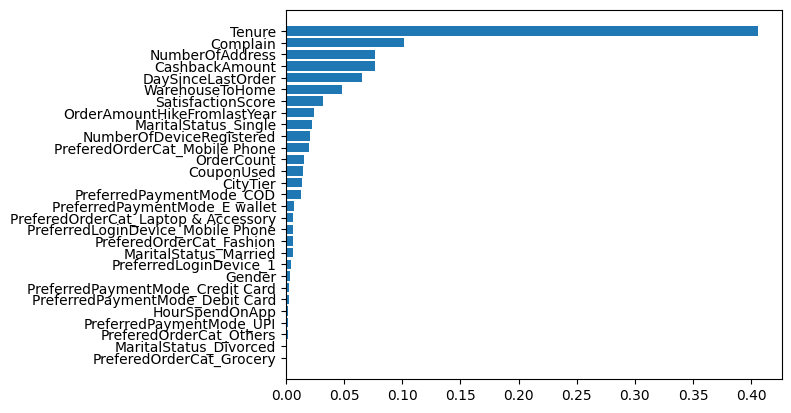

In [ ]:
import matplotlib.pyplot as plt
plt.barh(importances.feature, importances.importance)